## Поиск аномалий без учителя (Unsupervised Anomaly Detection)

В этом модуле мы решаем задачу детекции выбросов и подозрительных манипуляций с рейтингами:
1. **Отбор признаков**: используем числовые характеристики фильмов (рейтинг, сжатые голоса, индикатор аномальности, хронометраж, возраст).
2. **Масштабирование**: применяем `RobustScaler`, устойчивый к выбросам (на основе медианы и IQR).
3. **Модели поиска аномалий**: обучаем и сравниваем два разных подхода — **Isolation Forest** (изолирующие деревья) и **Local Outlier Factor (LOF)** (локальная плотность).
4. **Интерпретация**: находим конкретные подозрительные фильмы и визуализируем аномалии.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 2. Загрузка очищенного датасета
df = pd.read_csv('data/movies_clean.csv')
print(f"Датасет успешно загружен: {len(df):,} строк, {df.shape[1]} колонок")

# 3. Отбор признаков для поиска аномалий
feature_cols = ['averageRating', 'log_votes', 'rating_to_log_votes', 'runtimeMinutes', 'movie_age']
X = df[feature_cols].copy()

print("\nПризнаки для анализа аномалий:")
X.head()

Датасет успешно загружен: 313,025 строк, 13 колонок

Признаки для анализа аномалий:


,averageRating,log_votes,rating_to_log_votes,runtimeMinutes,movie_age
0,5.3,2.378398,1.568791,45,132
1,5.3,2.788168,1.399093,100,129
2,6.0,3.041393,1.484637,70,120
3,5.0,1.623249,1.906033,90,119
4,5.0,1.929419,1.706823,120,118


### 2. Масштабирование признаков (RobustScaler)
Приводим признаки к сопоставимому масштабу. Почему именно **`RobustScaler`**:
- `StandardScaler` и `MinMaxScaler` сильно смещаются под влиянием выбросов.
- `RobustScaler` вычитает **медиану** и делит на **межквартильный размах (IQR = Q75 - Q25)**, поэтому сам скейлер устойчив к аномалиям, которые мы собираемся искать.

In [3]:
from sklearn.preprocessing import RobustScaler

# Инициализация и масштабирование матрицы признаков
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

print(f"Форма X_scaled: {X_scaled.shape}")
print("Медианы после скейлинга (центрированы в 0):", np.round(np.median(X_scaled, axis=0), 2))
print("Межквартильный размах IQR (приведён к 1):", np.round(np.percentile(X_scaled, 75, axis=0) - np.percentile(X_scaled, 25, axis=0), 2))

Форма X_scaled: (313025, 5)
Медианы после скейлинга (центрированы в 0): [0. 0. 0. 0. 0.]
Межквартильный размах IQR (приведён к 1): [1. 1. 1. 1. 1.]


### 3. Детекция аномалий: Isolation Forest (Изолирующий лес)
Обучаем ансамбль изолирующих деревьев.
- **Принцип**: аномалии редки и сильно отличаются от большинства, поэтому в случайных деревьях они изолируются в неглубоких листьях (за малое число разбиений).
- **Параметры**:
  - `contamination=0.01`: ожидаем около 1% аномалий (3 130 фильмов).
  - `n_estimators=100`: 100 независимых деревьев для стабильного усреднения длины пути.
  - `random_state=42`: фиксация случайности для воспроизводимости.
  - `n_jobs=-1`: параллельное обучение на всех доступных ядрах процессора.

In [4]:
from sklearn.ensemble import IsolationForest

# 1. Инициализация модели Isolation Forest
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# 2. Обучение модели на смасштабированных признаках
iso_forest.fit(X_scaled)

# 3. Получение меток (1: норма, -1: аномалия) и непрерывного скора
df['anomaly_iforest'] = iso_forest.predict(X_scaled)
df['score_iforest'] = iso_forest.decision_function(X_scaled)

n_anomalies = (df['anomaly_iforest'] == -1).sum()
print(f"Всего фильмов: {len(df):,}")
print(f"Обнаружено аномалий: {n_anomalies:,} ({n_anomalies / len(df):.2%})")
print("\nРаспределение скоров аномальности (score_iforest):")
print(df['score_iforest'].describe().round(3))

Всего фильмов: 313,025
Обнаружено аномалий: 3,131 (1.00%)

Распределение скоров аномальности (score_iforest):
count    313025.000
mean          0.152
std           0.051
min          -0.140
25%           0.124
50%           0.164
75%           0.191
max           0.229
Name: score_iforest, dtype: float64


### 4. Интерпретация, визуализация и экспорт аномалий
1. **Анализ Top-10**: исследуем самые экстремальные выбросы, пойманные моделью (накрученные оценки при малом числе голосов, аномальный хронометраж).
2. **Визуализация**: строим послойный Scatter plot (норма против аномалий).
3. **Экспорт**: сохраняем `data/movies_with_anomalies.csv` с новыми признаками для последующего этапа контролируемого машинного обучения.

Топ-10 наиболее выраженных аномалий (по наименьшему score_iforest):



,primaryTitle,startYear,averageRating,numVotes,runtimeMinutes,rating_to_log_votes,score_iforest
1421,Terror Trail,1921,1.6,24,360,0.672209,-0.140305
154,The Trey o' Hearts,1914,2.1,25,310,0.875752,-0.123378
2160,Idaho,1925,1.6,20,200,0.695341,-0.120950
3330,Vultures of the Sea,1928,2.0,23,200,0.846838,-0.113041
1034,The Tiger's Trail,1919,2.7,23,300,1.143231,-0.107676
968,A Man's Fight,1919,1.4,26,50,0.579717,-0.106096
81933,The Lord Loves the Irish,1919,1.6,28,50,0.653820,-0.104656
1429,The Torrent,1921,1.6,16,50,0.725913,-0.104497
870,Bare-Fisted Gallagher,1919,1.8,10,50,0.900000,-0.103947
21129,Seven Samurai,1954,8.6,406847,207,1.301171,-0.101335


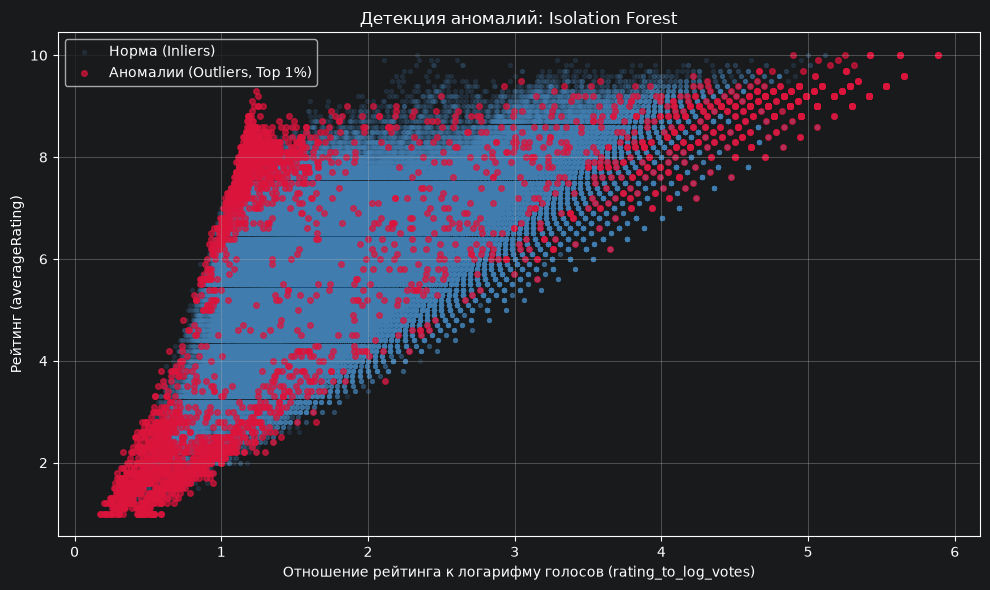


Датасет с аномалиями успешно сохранен: data/movies_with_anomalies.csv (313,025 строк, 15 колонок)


In [10]:
# 1. Топ-10 наиболее выраженных аномалий
inspect_cols = ['primaryTitle', 'startYear', 'averageRating', 'numVotes', 'runtimeMinutes', 'rating_to_log_votes', 'score_iforest']
top_anomalies = df[df['anomaly_iforest'] == -1].sort_values('score_iforest').head(10)

print("Топ-10 наиболее выраженных аномалий (по наименьшему score_iforest):\n")
# Приколы Jupyter/PyCharm
display(top_anomalies[inspect_cols])

# 2. Визуализация: распределение нормы и выбросов
plt.figure(figsize=(10, 6))

# Фоновый слой: обычные фильмы (полупрозрачные)
plt.scatter(
    df.loc[df['anomaly_iforest'] == 1, 'rating_to_log_votes'],
    df.loc[df['anomaly_iforest'] == 1, 'averageRating'],
    c='steelblue', alpha=0.15, s=8, label='Норма (Inliers)'
)

# Контрастный слой: аномалии (яркие, поверх нормы)
plt.scatter(
    df.loc[df['anomaly_iforest'] == -1, 'rating_to_log_votes'],
    df.loc[df['anomaly_iforest'] == -1, 'averageRating'],
    c='crimson', alpha=0.7, s=16, label='Аномалии (Outliers, Top 1%)'
)

plt.xlabel('Отношение рейтинга к логарифму голосов (rating_to_log_votes)')
plt.ylabel('Рейтинг (averageRating)')
plt.title('Детекция аномалий: Isolation Forest')
plt.grid()
plt.legend()
plt.tight_layout()
plt.show()

# 3. Экспорт датасета с разметкой аномалий на диск
output_path = 'data/movies_with_anomalies.csv'
df.to_csv(output_path, index=False)
print(f"\nДатасет с аномалиями успешно сохранен: {output_path} ({df.shape[0]:,} строк, {df.shape[1]} колонок)")